In [1]:
# =============================================================================
# Cell 1 — Build monthly valid-day counts from DAILY OC-CCI Rrs_665
# =============================================================================
#
# Scientific definition used here
# -------------------------------
# This notebook intentionally does NOT use `total_nobs_sum`.
#
# For each 4-km OC-CCI pixel and each calendar month:
#   valid_days = number of DAILY OC-CCI files in which Rrs_665 is valid.
#
# Therefore the pixel-level count is bounded by the number of calendar days
# in that month (28/29/30/31). A daily merged OC-CCI value can itself contain
# information from more than one sensor, but it is counted only once here.
# The resulting metric should therefore be described as "valid observation
# days", not as the number of independent satellite scenes.
#
# Section-level monthly values saved and plotted later:
#   mean(valid_days)   across all eligible 4-km pixels touched by that section;
#   median(valid_days) across all eligible 4-km pixels touched by that section.
#
# Both statistics use the same fixed eligible-pixel footprint, so a pixel with
# zero valid retrieval days in a given month contributes 0 to both summaries.
#
# "Eligible" is defined once, over the full 2003-2024 period: a section pixel
# must have at least one valid daily Rrs_665 value somewhere in the full record.
# For an eligible pixel, a month with no valid daily retrieval contributes ZERO.
# This avoids survivorship bias from averaging only pixels that happened to be
# valid in a particular month.
# =============================================================================

from pathlib import Path
from datetime import datetime
from contextlib import contextmanager
import calendar
import json
import os
import re
import sys
import warnings

# Prevent nested BLAS/OpenMP threads inside each worker process.
# The outer parallelism is handled explicitly with up to 28 processes.
for _env_name in (
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
):
    os.environ[_env_name] = "1"

# Read-only HDF5/NetCDF workload on a shared filesystem. Disabling file locking
# avoids unnecessary lock traffic on many HPC filesystems.
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")

import numpy as np
import pandas as pd
from netCDF4 import Dataset
from tqdm import tqdm
import joblib
from joblib import Parallel, delayed

# PROJ-safe vector handling (avoids GeoPandas/Rasterio dependence for masks)
_conda_proj = Path(sys.prefix) / "share" / "proj"
if (_conda_proj / "proj.db").exists():
    os.environ["PROJ_DATA"] = str(_conda_proj)
    os.environ["PROJ_LIB"] = str(_conda_proj)

import pyproj
pyproj.datadir.set_data_dir(pyproj.datadir.get_data_dir())
import shapefile
from shapely.geometry import shape, box
from shapely.ops import transform as transform_geometry, unary_union
from shapely.prepared import prep


# =============================================================================
# User settings
# =============================================================================
# Existing OC-CCI v6.0 DAILY Rrs archive used in the Louisiana workflow.
# Expected structure:
#   /projectnb/nasa-marsh/Hangjie/cloud/tss/2003/*.nc
#   /projectnb/nasa-marsh/Hangjie/cloud/tss/2004/*.nc
#   ...
# with filenames similar to:
#   ESACCI-OC-L3S-RRS-MERGED-1D_DAILY_4km_GEO_PML_RRS-YYYYMMDD-fv6.0.nc
DAILY_ROOT = Path("/projectnb/nasa-marsh/Hangjie/cloud/tss")

SECTION_VECTOR = Path(
    "/projectnb/nasa-marsh/Hangjie/Louisiana/bathymetry/4m_isobath_20260423.shp"
)
OUT_DIR = Path("/projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts")
OUT_DIR.mkdir(parents=True, exist_ok=True)

YEAR_START = 2003
YEAR_END = 2024

# Same Louisiana domain used by the existing OC-CCI count workflow.
LON_MIN, LON_MAX = -94.0, -89.0
LAT_MIN, LAT_MAX = 28.5, 30.5

RRS_VAR = "Rrs_665"

# Keep this as None to match the existing SSC notebook, which treats any finite,
# non-fill Rrs_665 value as valid. Set to 0.0 only if you deliberately want to
# reject negative Rrs values.
RRS_MIN = None

# Archive gaps are allowed. Missing daily files are reported and recorded in the
# metadata, but they do not stop the calculation. Only daily files that actually
# exist are read; a missing day therefore cannot contribute a valid Rrs_665 day.
# With only a small fraction of days missing, this has negligible influence on
# the section-scale climatology while keeping the workflow robust.
REQUIRE_COMPLETE_DAILY_ARCHIVE = False

# -----------------------------------------------------------------------------
# HPC settings
# -----------------------------------------------------------------------------
# This notebook uses process-based parallelism for NetCDF/HDF5 safety and to
# accelerate the dominant cost: opening and reading ~8,000 daily files.
#
# IMPORTANT: a notebook cannot enlarge the CPU/RAM allocation granted by the
# cluster scheduler after the session has started. Start the SCC/Jupyter job with
# 28 CPU cores and up to 300 GB RAM if you want the full allocation available.
# The workload itself is memory-light and will normally use only a small fraction
# of 300 GB; allocating unused RAM does not make the I/O faster.
MAX_WORKERS = 28
MEMORY_BUDGET_GB = 300.0

def _visible_cpu_count():
    """Return the CPU count visible to the current scheduler/cgroup allocation."""
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1

VISIBLE_CPUS = _visible_cpu_count()
N_WORKERS = min(MAX_WORKERS, VISIBLE_CPUS)

print(f"Visible CPU cores : {VISIBLE_CPUS}")
print(f"Worker processes  : {N_WORKERS} (cap = {MAX_WORKERS})")
print(f"RAM budget cap    : {MEMORY_BUDGET_GB:.0f} GB (scheduler-side allocation)")
if N_WORKERS < MAX_WORKERS:
    warnings.warn(
        f"Only {VISIBLE_CPUS} CPU core(s) are visible to this notebook, so the "
        f"28-worker target cannot be reached in the current allocation."
    )

# Section identification. Leave both as None to use the same verified fallback
# as the existing workflow when the shapefile contains exactly four records.
SECTION_FIELD = None
SECTION_IDS_BY_RECORD = None
SECTION_CRS_OVERRIDE = None

PERIOD = f"{YEAR_START}_{YEAR_END}"
NPZ_OUT = OUT_DIR / f"Louisiana_daily_Rrs665_valid_days_by_month_{PERIOD}.npz"

# Combined tables containing both section mean and section median statistics.
MONTHLY_CSV_OUT = OUT_DIR / f"Louisiana_section_valid_Rrs665_days_monthly_timeseries_{PERIOD}.csv"
CLIM_CSV_OUT = OUT_DIR / f"Louisiana_section_valid_Rrs665_days_monthly_climatology_{PERIOD}.csv"

# Explicit metric-specific tables for direct reuse.
MEAN_MONTHLY_CSV_OUT = OUT_DIR / f"Louisiana_section_mean_valid_Rrs665_days_monthly_timeseries_{PERIOD}.csv"
MEDIAN_MONTHLY_CSV_OUT = OUT_DIR / f"Louisiana_section_median_valid_Rrs665_days_monthly_timeseries_{PERIOD}.csv"
MEAN_CLIM_CSV_OUT = OUT_DIR / f"Louisiana_section_mean_valid_Rrs665_days_monthly_climatology_{PERIOD}.csv"
MEDIAN_CLIM_CSV_OUT = OUT_DIR / f"Louisiana_section_median_valid_Rrs665_days_monthly_climatology_{PERIOD}.csv"

SECTION_CSV_OUT = OUT_DIR / f"Louisiana_section_valid_Rrs665_days_summary_{PERIOD}.csv"
META_OUT = OUT_DIR / f"Louisiana_section_valid_Rrs665_days_metadata_{PERIOD}.json"


# =============================================================================
# Helpers: files, NetCDF, and dates
# =============================================================================
def _date_from_daily_filename(path):
    """Extract YYYYMMDD from a daily OC-CCI filename."""
    name = path.name

    # Preferred OC-CCI daily naming pattern.
    m = re.search(r"RRS-(\d{8})(?:-|_|\.)", name)
    if m is None:
        # Conservative fallback: any isolated YYYYMMDD token.
        m = re.search(r"(?<!\d)((?:19|20)\d{6})(?!\d)", name)
    if m is None:
        return None

    try:
        return pd.Timestamp(datetime.strptime(m.group(1), "%Y%m%d").date())
    except ValueError:
        return None


def _discover_daily_files():
    """Return a complete, unique date->file table for the requested period."""
    records = []

    for year in range(YEAR_START, YEAR_END + 1):
        year_dir = DAILY_ROOT / str(year)
        if year_dir.is_dir():
            candidates = sorted(year_dir.glob("*.nc"))
        else:
            # Small fallback search in the root only; no expensive recursive scan.
            candidates = sorted(DAILY_ROOT.glob(f"*{year}*.nc"))

        for path in candidates:
            # Ignore non-daily or non-RRS products if they coexist in the folder.
            upper = path.name.upper()
            if "DAILY" not in upper or "RRS" not in upper or "4KM" not in upper:
                continue

            date = _date_from_daily_filename(path)
            if date is None:
                continue
            if YEAR_START <= date.year <= YEAR_END:
                records.append((date, path))

    if not records:
        raise FileNotFoundError(
            f"No daily OC-CCI Rrs NetCDF files were found under {DAILY_ROOT}. "
            "Check DAILY_ROOT and the year-subfolder structure."
        )

    df = pd.DataFrame(records, columns=["date", "path"]).sort_values("date")

    duplicates = df[df.duplicated("date", keep=False)]
    if not duplicates.empty:
        preview = duplicates.head(20).to_string(index=False)
        raise ValueError(
            "More than one daily file was found for at least one date. "
            "Resolve duplicates before counting valid days.\n" + preview
        )

    expected = pd.date_range(
        f"{YEAR_START}-01-01", f"{YEAR_END}-12-31", freq="D"
    ).normalize()
    found = pd.DatetimeIndex(df["date"])
    missing = expected.difference(found)

    print(f"Daily files found : {len(df):,}")
    print(f"Expected days     : {len(expected):,}")
    print(f"Missing days      : {len(missing):,}")

    if len(missing) > 0:
        msg = (
            f"The daily archive is missing {len(missing)} expected date(s). "
            f"These dates will be skipped. First missing dates: "
            f"{list(missing[:20].strftime('%Y-%m-%d'))}"
        )
        if REQUIRE_COMPLETE_DAILY_ARCHIVE:
            raise FileNotFoundError(msg)
        warnings.warn(msg)

    return df.reset_index(drop=True), expected, missing


def _find_dim_name(var, kind):
    aliases = {
        "lat": {"lat", "latitude", "y"},
        "lon": {"lon", "longitude", "x"},
        "time": {"time", "t"},
    }
    dims = list(var.dimensions)

    for dim in dims:
        if dim.lower() in aliases[kind]:
            return dim
    for dim in dims:
        d = dim.lower()
        if kind == "lat" and "lat" in d:
            return dim
        if kind == "lon" and "lon" in d:
            return dim
        if kind == "time" and "time" in d:
            return dim
    return None


def _read_2d_subset(ds, var_name, lat_slice, lon_slice):
    """Read only the requested subset and return a float array [lat, lon]."""
    if var_name not in ds.variables:
        related = [name for name in ds.variables if "rrs" in name.lower()]
        raise KeyError(
            f"{var_name!r} not found in {Path(ds.filepath()).name}. "
            f"Rrs-like variables: {related}"
        )

    var = ds.variables[var_name]
    dims = list(var.dimensions)
    lat_dim = _find_dim_name(var, "lat")
    lon_dim = _find_dim_name(var, "lon")
    time_dim = _find_dim_name(var, "time")

    if lat_dim is None or lon_dim is None:
        raise ValueError(f"Cannot identify lat/lon dimensions for {var_name}: {dims}")

    indexer = []
    kept_dims = []
    for axis, dim in enumerate(dims):
        if dim == lat_dim:
            indexer.append(lat_slice)
            kept_dims.append(dim)
        elif dim == lon_dim:
            indexer.append(lon_slice)
            kept_dims.append(dim)
        elif dim == time_dim:
            indexer.append(0)
        elif var.shape[axis] == 1:
            indexer.append(0)
        else:
            raise ValueError(
                f"Unexpected non-singleton dimension {dim!r} "
                f"(size={var.shape[axis]}) for {var_name!r}."
            )

    arr = var[tuple(indexer)]
    if np.ma.isMaskedArray(arr):
        arr = arr.astype(np.float64).filled(np.nan)
    arr = np.asarray(arr, dtype=np.float64).squeeze()

    if arr.ndim != 2:
        raise ValueError(f"{var_name!r} did not reduce to 2-D; shape={arr.shape}")

    if kept_dims == [lat_dim, lon_dim]:
        pass
    elif kept_dims == [lon_dim, lat_dim]:
        arr = arr.T
    else:
        raise ValueError(f"Unexpected retained dimension order: {kept_dims}")

    return arr


# =============================================================================
# Helpers: parallel monthly counting
# =============================================================================
@contextmanager
def _tqdm_joblib(tqdm_object):
    """Connect joblib batch-completion callbacks to a tqdm progress bar."""
    old_callback = joblib.parallel.BatchCompletionCallBack

    class TqdmBatchCompletionCallback(old_callback):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_callback
        tqdm_object.close()


def _count_one_month(
    task_index,
    period_string,
    nc_paths,
    lat_start,
    lat_stop,
    lon_start,
    lon_stop,
    nlat,
    nlon,
    rrs_var,
    rrs_min,
):
    """
    Count valid DAILY Rrs_665 retrieval days for one calendar month.

    One worker owns one month at a time, so no shared writable array is needed.
    This keeps synchronization overhead and memory use extremely small.
    """
    period = pd.Period(period_string, freq="M")
    count = np.zeros((nlat, nlon), dtype=np.uint8)

    lat_slice_local = slice(lat_start, lat_stop)
    lon_slice_local = slice(lon_start, lon_stop)

    for nc_path in nc_paths:
        with Dataset(nc_path, "r") as ds:
            rrs = _read_2d_subset(
                ds, rrs_var, lat_slice_local, lon_slice_local
            )

        valid = np.isfinite(rrs)
        if rrs_min is not None:
            valid &= rrs >= rrs_min

        count += valid.astype(np.uint8, copy=False)

    max_allowed = calendar.monthrange(period.year, period.month)[1]
    if int(count.max()) > max_allowed:
        raise AssertionError(
            f"{period}: a pixel has {int(count.max())} valid days, "
            f"exceeding the {max_allowed} calendar days."
        )

    return task_index, count, len(nc_paths)


# =============================================================================
# Helpers: section geometries and native-grid masks
# =============================================================================
def _read_vectors(path, crs_override=None):
    if not path.is_file():
        raise FileNotFoundError(path)

    prj = path.with_suffix(".prj")
    if crs_override is None and not prj.is_file():
        raise ValueError(f"Missing CRS file: {prj}. Supply SECTION_CRS_OVERRIDE.")

    source_crs = pyproj.CRS.from_user_input(crs_override or prj.read_text())
    target_crs = pyproj.CRS.from_epsg(4326)
    transformer = pyproj.Transformer.from_crs(
        source_crs, target_crs, always_xy=True
    )

    result = []
    with shapefile.Reader(str(path)) as reader:
        fields = [v[0] for v in reader.fields[1:]]
        for sr in reader.iterShapeRecords():
            if sr.shape.shapeType == 0:
                continue
            geom = transform_geometry(
                transformer.transform, shape(sr.shape.__geo_interface__)
            )
            if geom.is_empty:
                continue
            if not geom.is_valid:
                raise ValueError(f"Invalid geometry in {path}; repair it first.")
            result.append((dict(zip(fields, list(sr.record))), geom))
    return result


def _section_number(value):
    m = re.fullmatch(
        r"(?:section[\s_-]*)?([1-4])(?:\.0+)?",
        str(value).strip(),
        flags=re.I,
    )
    return int(m.group(1)) if m else None


def _read_sections():
    records = _read_vectors(SECTION_VECTOR, SECTION_CRS_OVERRIDE)
    if not records:
        raise ValueError("The section vector is empty.")

    fields = list(records[0][0])
    candidates = [SECTION_FIELD] if SECTION_FIELD else [
        field
        for wanted in ("section", "section_id", "name", "id", "label", "seg", "segment")
        for field in fields
        if field.lower() == wanted
    ]

    ids = None
    used = None
    if SECTION_IDS_BY_RECORD is not None:
        ids = list(SECTION_IDS_BY_RECORD)
        used = "explicit record mapping"
    else:
        for field in candidates:
            trial = [_section_number(attrs.get(field)) for attrs, _ in records]
            if set(trial) == {1, 2, 3, 4}:
                ids = trial
                used = field
                break

        if ids is None and len(records) == 4:
            warnings.warn(
                "No section-ID attribute was found; using the four-feature record "
                "order, matching the existing SSC workflow. Verify the labels once."
            )
            ids = [1, 2, 3, 4]
            used = "four-feature record order"

    if ids is None or len(ids) != len(records) or set(ids) != {1, 2, 3, 4}:
        raise ValueError(
            f"Cannot verify Section 1-4 IDs. Available fields: {fields}. "
            "Set SECTION_FIELD or SECTION_IDS_BY_RECORD."
        )

    geometries = {
        sec: unary_union(
            [geom for sid, (_, geom) in zip(ids, records) if sid == sec]
        )
        for sec in range(1, 5)
    }
    return geometries, used


def _edges(centers):
    centers = np.asarray(centers, dtype=float)
    delta = np.diff(centers)
    if not (np.all(delta > 0) or np.all(delta < 0)):
        raise ValueError("Grid coordinates must be strictly monotonic.")
    return np.r_[
        centers[0] - delta[0] / 2,
        (centers[:-1] + centers[1:]) / 2,
        centers[-1] + delta[-1] / 2,
    ]


def _section_masks(geometries, lon, lat):
    """Native-grid all-touched masks, matching the intent of the SSC notebook."""
    xe = _edges(lon)
    ye = _edges(lat)
    masks = {}

    for sec, geom in geometries.items():
        prepared = prep(geom)
        xmin, ymin, xmax, ymax = geom.bounds

        jj = np.flatnonzero(
            (np.minimum(xe[:-1], xe[1:]) <= xmax)
            & (np.maximum(xe[:-1], xe[1:]) >= xmin)
        )
        ii = np.flatnonzero(
            (np.minimum(ye[:-1], ye[1:]) <= ymax)
            & (np.maximum(ye[:-1], ye[1:]) >= ymin)
        )

        mask = np.zeros((lat.size, lon.size), dtype=bool)
        for i in ii:
            for j in jj:
                cell = box(
                    min(xe[j], xe[j + 1]),
                    min(ye[i], ye[i + 1]),
                    max(xe[j], xe[j + 1]),
                    max(ye[i], ye[i + 1]),
                )
                mask[i, j] = prepared.intersects(cell)

        if not mask.any():
            raise ValueError(f"Section {sec} does not intersect the requested grid.")
        masks[f"Section-{sec}"] = mask

    masks["Entire Section"] = np.logical_or.reduce(list(masks.values()))
    return masks


# =============================================================================
# 1. Discover the daily archive
# =============================================================================
daily_df, expected_days, missing_days = _discover_daily_files()
if len(missing_days) > 0 and not REQUIRE_COMPLETE_DAILY_ARCHIVE:
    missing_fraction = 100.0 * len(missing_days) / len(expected_days)
    print(
        f"Continuing with available daily files; missing fraction = "
        f"{missing_fraction:.3f}% of expected days."
    )
daily_df["year"] = daily_df["date"].dt.year
daily_df["month"] = daily_df["date"].dt.month
daily_df["period"] = daily_df["date"].dt.to_period("M")

month_periods = pd.period_range(
    f"{YEAR_START}-01", f"{YEAR_END}-12", freq="M"
)


# =============================================================================
# 2. Read native OC-CCI grid and define Louisiana subset
# =============================================================================
first_file = Path(daily_df.iloc[0]["path"])
with Dataset(first_file, "r") as ds0:
    if "lon" not in ds0.variables or "lat" not in ds0.variables:
        raise KeyError("Expected coordinate variables `lon` and `lat` were not found.")
    lon_full = np.asarray(ds0.variables["lon"][:], dtype=np.float64).squeeze()
    lat_full = np.asarray(ds0.variables["lat"][:], dtype=np.float64).squeeze()

if lon_full.ndim != 1 or lat_full.ndim != 1:
    raise ValueError("This notebook expects one-dimensional lon/lat coordinates.")

lon_idx = np.where((lon_full >= LON_MIN) & (lon_full <= LON_MAX))[0]
lat_idx = np.where((lat_full >= LAT_MIN) & (lat_full <= LAT_MAX))[0]
if lon_idx.size == 0 or lat_idx.size == 0:
    raise ValueError("Requested Louisiana extent does not intersect the OC-CCI grid.")

lon_slice = slice(int(lon_idx.min()), int(lon_idx.max()) + 1)
lat_slice = slice(int(lat_idx.min()), int(lat_idx.max()) + 1)
lon_native = lon_full[lon_slice]
lat_native = lat_full[lat_slice]

nlat = lat_native.size
nlon = lon_native.size
print(f"Louisiana subset : {nlat} lat x {nlon} lon pixels")
print(f"Nominal grid     : {abs(np.nanmedian(np.diff(lon_native))):.8f}° x "
      f"{abs(np.nanmedian(np.diff(lat_native))):.8f}°")


# =============================================================================
# 3. Count DAILY valid Rrs_665 days for every pixel in every month
#    Parallelized by calendar month with up to 28 worker processes.
# =============================================================================
monthly_valid_days = np.zeros(
    (len(month_periods), nlat, nlon), dtype=np.uint8
)
files_found_per_month = np.zeros(len(month_periods), dtype=np.uint8)

files_by_period = {
    period: group.sort_values("date")
    for period, group in daily_df.groupby("period", sort=True)
}

# Build small independent tasks. Each task reads all available daily files for
# one month and returns one [lat, lon] uint8 count map. At most 28 NetCDF files
# are opened concurrently (one per worker), which is much faster than the serial
# loop while avoiding thousands of tiny inter-process tasks.
tasks = []
for t, period in enumerate(month_periods):
    group = files_by_period.get(period)
    nc_paths = [] if group is None else [str(p) for p in group["path"].tolist()]

    if group is None and REQUIRE_COMPLETE_DAILY_ARCHIVE:
        raise FileNotFoundError(f"No daily files found for {period}.")

    tasks.append(
        (
            t,
            str(period),
            nc_paths,
            int(lat_slice.start),
            int(lat_slice.stop),
            int(lon_slice.start),
            int(lon_slice.stop),
            int(nlat),
            int(nlon),
            RRS_VAR,
            RRS_MIN,
        )
    )

print(
    f"Parallel counting: {len(tasks)} monthly tasks, "
    f"{N_WORKERS} worker processes, {len(daily_df):,} daily files."
)

# `loky` uses separate worker processes and cloudpickle, which is robust inside
# Jupyter notebooks and avoids unsafe multithreaded NetCDF/HDF5 access.
with _tqdm_joblib(tqdm(total=len(tasks), desc="Counting valid Rrs_665 days by month")):
    results = Parallel(
        n_jobs=N_WORKERS,
        backend="loky",
        batch_size=1,
        pre_dispatch=N_WORKERS,
        max_nbytes=None,
    )(
        delayed(_count_one_month)(*task) for task in tasks
    )

for t, count, n_files in results:
    monthly_valid_days[t] = count
    files_found_per_month[t] = n_files

# Sanity checks after all workers finish.
for t, period in enumerate(month_periods):
    max_allowed = calendar.monthrange(period.year, period.month)[1]
    if int(monthly_valid_days[t].max()) > max_allowed:
        raise AssertionError(
            f"{period}: monthly count exceeds the number of calendar days."
        )


# =============================================================================
# 4. Reorder grid to longitude ascending, latitude descending
# =============================================================================
lon_order = np.argsort(lon_native)
lat_order = np.argsort(lat_native)[::-1]
lon = lon_native[lon_order]
lat = lat_native[lat_order]
monthly_valid_days = monthly_valid_days[:, lat_order, :][:, :, lon_order]

# Static water/retrieval footprint: valid at least once in the full record.
ever_valid = monthly_valid_days.max(axis=0) > 0

# Pixel-wise monthly climatology used by the 12-panel Louisiana map.
# For each calendar month (Jan, Feb, ..., Dec), take the median across years
# of the monthly valid-day count at every 4-km pixel. Eligible pixels with zero
# valid days in a particular year-month remain zero; pixels that are never valid
# anywhere in 2003-2024 are masked as NaN in the climatology.
pixel_median_valid_observation_climatology = np.full(
    (12, nlat, nlon), np.nan, dtype=np.float32
)

_month_numbers = np.array([p.month for p in month_periods], dtype=np.int8)
for _month in range(1, 13):
    _sel = _month_numbers == _month
    _median_map = np.median(
        monthly_valid_days[_sel].astype(np.float32),
        axis=0,
    )
    _median_map[~ever_valid] = np.nan
    pixel_median_valid_observation_climatology[_month - 1] = _median_map


# =============================================================================
# 5. Build section masks and monthly section statistics
# =============================================================================
section_geometries, section_field_used = _read_sections()
masks = _section_masks(section_geometries, lon, lat)

section_order = [
    "Section-1", "Section-2", "Section-3", "Section-4", "Entire Section"
]

monthly_rows = []
section_rows = []

for label in section_order:
    mask = masks[label]
    eligible = mask & ever_valid
    n_mask = int(mask.sum())
    n_eligible = int(eligible.sum())

    if n_eligible == 0:
        raise ValueError(f"{label}: no pixel is valid anywhere in 2003-2024.")

    # Shape = [264 months, eligible pixels].
    values = monthly_valid_days[:, eligible].astype(np.float64)

    section_rows.append(
        {
            "section": label,
            "grid_pixels_touched": n_mask,
            "eligible_pixels_ever_valid": n_eligible,
            "eligible_fraction": n_eligible / n_mask,
            "full_period_mean_valid_days_per_pixel_per_month": float(values.mean()),
            "full_period_median_valid_days_per_pixel_per_month": float(np.median(values)),
        }
    )

    for t, period in enumerate(month_periods):
        v = values[t]
        calendar_days = calendar.monthrange(period.year, period.month)[1]

        monthly_rows.append(
            {
                "date": period.to_timestamp(),
                "year": period.year,
                "month": period.month,
                "calendar_days": calendar_days,
                "daily_files_found": int(files_found_per_month[t]),
                "section": label,
                "grid_pixels_touched": n_mask,
                "eligible_pixels": n_eligible,
                # Primary plotted metric:
                "mean_valid_days_per_eligible_pixel": float(np.mean(v)),
                # Additional robust/spatial-distribution diagnostics:
                "median_valid_days_per_eligible_pixel": float(np.median(v)),
                "p25_valid_days_per_eligible_pixel": float(np.quantile(v, 0.25)),
                "p75_valid_days_per_eligible_pixel": float(np.quantile(v, 0.75)),
                "min_valid_days_per_eligible_pixel": float(np.min(v)),
                "max_valid_days_per_eligible_pixel": float(np.max(v)),
                "pixels_with_at_least_one_valid_day": int(np.count_nonzero(v > 0)),
                "fraction_eligible_pixels_with_at_least_one_valid_day": float(np.mean(v > 0)),
            }
        )

monthly_df = pd.DataFrame(monthly_rows).sort_values(["section", "date"]).reset_index(drop=True)
section_df = pd.DataFrame(section_rows)


# =============================================================================
# 6. Monthly climatology of BOTH section-level monthly metrics
# =============================================================================
# For every section we first calculate one spatial statistic per month:
#   1) spatial mean   of valid-day counts across eligible section pixels;
#   2) spatial median of valid-day counts across eligible section pixels.
#
# We then summarize all January values, all February values, etc. across years.
# The plotting cell uses the across-year mean as the climatology line and the
# across-year 25th-75th percentile range as the shaded envelope, exactly as in
# the original SSC figure.
VALUE_COLS = [
    "mean_valid_days_per_eligible_pixel",
    "median_valid_days_per_eligible_pixel",
]

clim_rows = []

for value_col in VALUE_COLS:
    for label in section_order:
        sub = monthly_df[monthly_df["section"] == label]
        grouped = sub.groupby("month")[value_col]

        stats = pd.DataFrame(
            {
                "mean": grouped.mean(),
                "std": grouped.std(),
                "median": grouped.median(),
                "p25": grouped.quantile(0.25),
                "p75": grouped.quantile(0.75),
                "min": grouped.min(),
                "max": grouped.max(),
                "count": grouped.count(),
            }
        ).reset_index()
        stats["section"] = label
        stats["metric"] = value_col
        clim_rows.append(stats)

clim_df = (
    pd.concat(clim_rows, ignore_index=True)
    .sort_values(["metric", "section", "month"])
    .reset_index(drop=True)
)


# =============================================================================
# 7. Save outputs for plotting/audit
# =============================================================================
year_month = np.array([[p.year, p.month] for p in month_periods], dtype=np.int16)
np.savez_compressed(
    NPZ_OUT,
    lon=lon.astype(np.float64),
    lat=lat.astype(np.float64),
    monthly_valid_days=monthly_valid_days,
    ever_valid=ever_valid,
    year_month=year_month,
    files_found_per_month=files_found_per_month,
    pixel_median_valid_observation_climatology=(
        pixel_median_valid_observation_climatology
    ),
)

monthly_df.to_csv(MONTHLY_CSV_OUT, index=False)
clim_df.to_csv(CLIM_CSV_OUT, index=False)
section_df.to_csv(SECTION_CSV_OUT, index=False)

# Save explicit mean and median monthly tables. These retain all identifying
# columns so each section-month value is fully traceable.
base_monthly_cols = [
    "date",
    "year",
    "month",
    "calendar_days",
    "daily_files_found",
    "section",
    "grid_pixels_touched",
    "eligible_pixels",
]

mean_monthly_df = monthly_df[
    base_monthly_cols + ["mean_valid_days_per_eligible_pixel"]
].copy()

median_monthly_df = monthly_df[
    base_monthly_cols + ["median_valid_days_per_eligible_pixel"]
].copy()

mean_monthly_df.to_csv(MEAN_MONTHLY_CSV_OUT, index=False)
median_monthly_df.to_csv(MEDIAN_MONTHLY_CSV_OUT, index=False)

mean_clim_df = (
    clim_df[clim_df["metric"] == "mean_valid_days_per_eligible_pixel"]
    .copy()
    .reset_index(drop=True)
)
median_clim_df = (
    clim_df[clim_df["metric"] == "median_valid_days_per_eligible_pixel"]
    .copy()
    .reset_index(drop=True)
)

mean_clim_df.to_csv(MEAN_CLIM_CSV_OUT, index=False)
median_clim_df.to_csv(MEDIAN_CLIM_CSV_OUT, index=False)

metadata = {
    "period": [YEAR_START, YEAR_END],
    "daily_root": str(DAILY_ROOT),
    "section_vector": str(SECTION_VECTOR),
    "section_id_field_or_rule": section_field_used,
    "Rrs_variable": RRS_VAR,
    "Rrs_min_filter": RRS_MIN,
    "metric": "daily valid Rrs_665 days per 4-km pixel per calendar month",
    "pixel_climatology": (
        "for each calendar month and pixel, median monthly valid-day count "
        "across 2003-2024; never-valid pixels are NaN"
    ),
    "section_month_metrics": {
        "mean": "mean valid days across static eligible section pixels",
        "median": "median valid days across static eligible section pixels",
    },
    "eligible_pixel_definition": "section pixel with >=1 valid daily Rrs_665 value anywhere in 2003-2024",
    "zero_handling": "eligible pixels with no valid retrieval in a given month contribute 0 days",
    "total_nobs_sum_used": False,
    "interpretation": (
        "Counts are valid daily merged-product days, not independent satellite scenes. "
        "Each pixel-day contributes at most 1, so a monthly pixel count cannot exceed "
        "the number of calendar days in that month."
    ),
    "missing_expected_daily_files": [d.strftime("%Y-%m-%d") for d in missing_days],
    "missing_daily_files_are_fatal": REQUIRE_COMPLETE_DAILY_ARCHIVE,
    "parallel_backend": "joblib loky process backend",
    "max_worker_processes": MAX_WORKERS,
    "worker_processes_used": N_WORKERS,
    "visible_cpu_cores": VISIBLE_CPUS,
    "memory_budget_gb": MEMORY_BUDGET_GB,
    "missing_day_handling": (
        "Missing daily files are skipped and cannot contribute a valid-day count; "
        "all missing dates are retained here for auditability."
    ),
}
META_OUT.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("\nFinished Cell 1.")
print(f"Saved monthly cube        : {NPZ_OUT}")
print(f"Saved combined table      : {MONTHLY_CSV_OUT}")
print(f"Saved combined climatology: {CLIM_CSV_OUT}")
print(f"Saved MEAN monthly table  : {MEAN_MONTHLY_CSV_OUT}")
print(f"Saved MEDIAN monthly table: {MEDIAN_MONTHLY_CSV_OUT}")
print(f"Saved MEAN climatology    : {MEAN_CLIM_CSV_OUT}")
print(f"Saved MEDIAN climatology  : {MEDIAN_CLIM_CSV_OUT}")
print(f"Saved section stats       : {SECTION_CSV_OUT}")
print(f"Saved metadata            : {META_OUT}")
print("\nSection-level monthly metrics:")
print("  1) mean valid Rrs_665 days per eligible 4-km pixel")
print("  2) median valid Rrs_665 days per eligible 4-km pixel")
print("  pixel-level maximum = 28/29/30/31, depending on month")
print("\nParallel resources:")
print(f"  worker processes used = {N_WORKERS} / {MAX_WORKERS}")
print(f"  configured RAM budget = {MEMORY_BUDGET_GB:.0f} GB (scheduler-side)")


/scratch/7775153.1.geo/ipykernel_717716/4154245870.py:252: UserWarning: The daily archive is missing 48 expected date(s). These dates will be skipped. First missing dates: ['2003-01-11', '2003-05-28', '2003-05-29', '2004-01-20', '2004-12-27', '2005-03-04', '2005-04-29', '2006-01-27', '2006-03-14', '2006-03-24', '2006-03-26', '2007-04-06', '2008-07-24', '2008-08-09', '2009-02-25', '2009-02-26', '2009-07-11', '2009-08-25', '2009-10-11', '2009-10-12']
  warnings.warn(msg)


Visible CPU cores : 32
Worker processes  : 28 (cap = 28)
RAM budget cap    : 300 GB (scheduler-side allocation)
Daily files found : 7,988
Expected days     : 8,036
Missing days      : 48
Continuing with available daily files; missing fraction = 0.597% of expected days.
Louisiana subset : 48 lat x 120 lon pixels
Nominal grid     : 0.04166667° x 0.04166667°
Parallel counting: 264 monthly tasks, 28 worker processes, 7,988 daily files.


Counting valid Rrs_665 days by month: 100%|███| 264/264 [00:02<00:00, 93.89it/s]



Finished Cell 1.
Saved monthly cube        : /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_daily_Rrs665_valid_days_by_month_2003_2024.npz
Saved combined table      : /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_valid_Rrs665_days_monthly_timeseries_2003_2024.csv
Saved combined climatology: /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_valid_Rrs665_days_monthly_climatology_2003_2024.csv
Saved MEAN monthly table  : /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_mean_valid_Rrs665_days_monthly_timeseries_2003_2024.csv
Saved MEDIAN monthly table: /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_median_valid_Rrs665_days_monthly_timeseries_2003_2024.csv
Saved MEAN climatology    : /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_mean_valid_Rrs665_days_monthly_climatology_2003_2024.csv
Saved MEDIAN climatology  : /projectnb/nasa-m

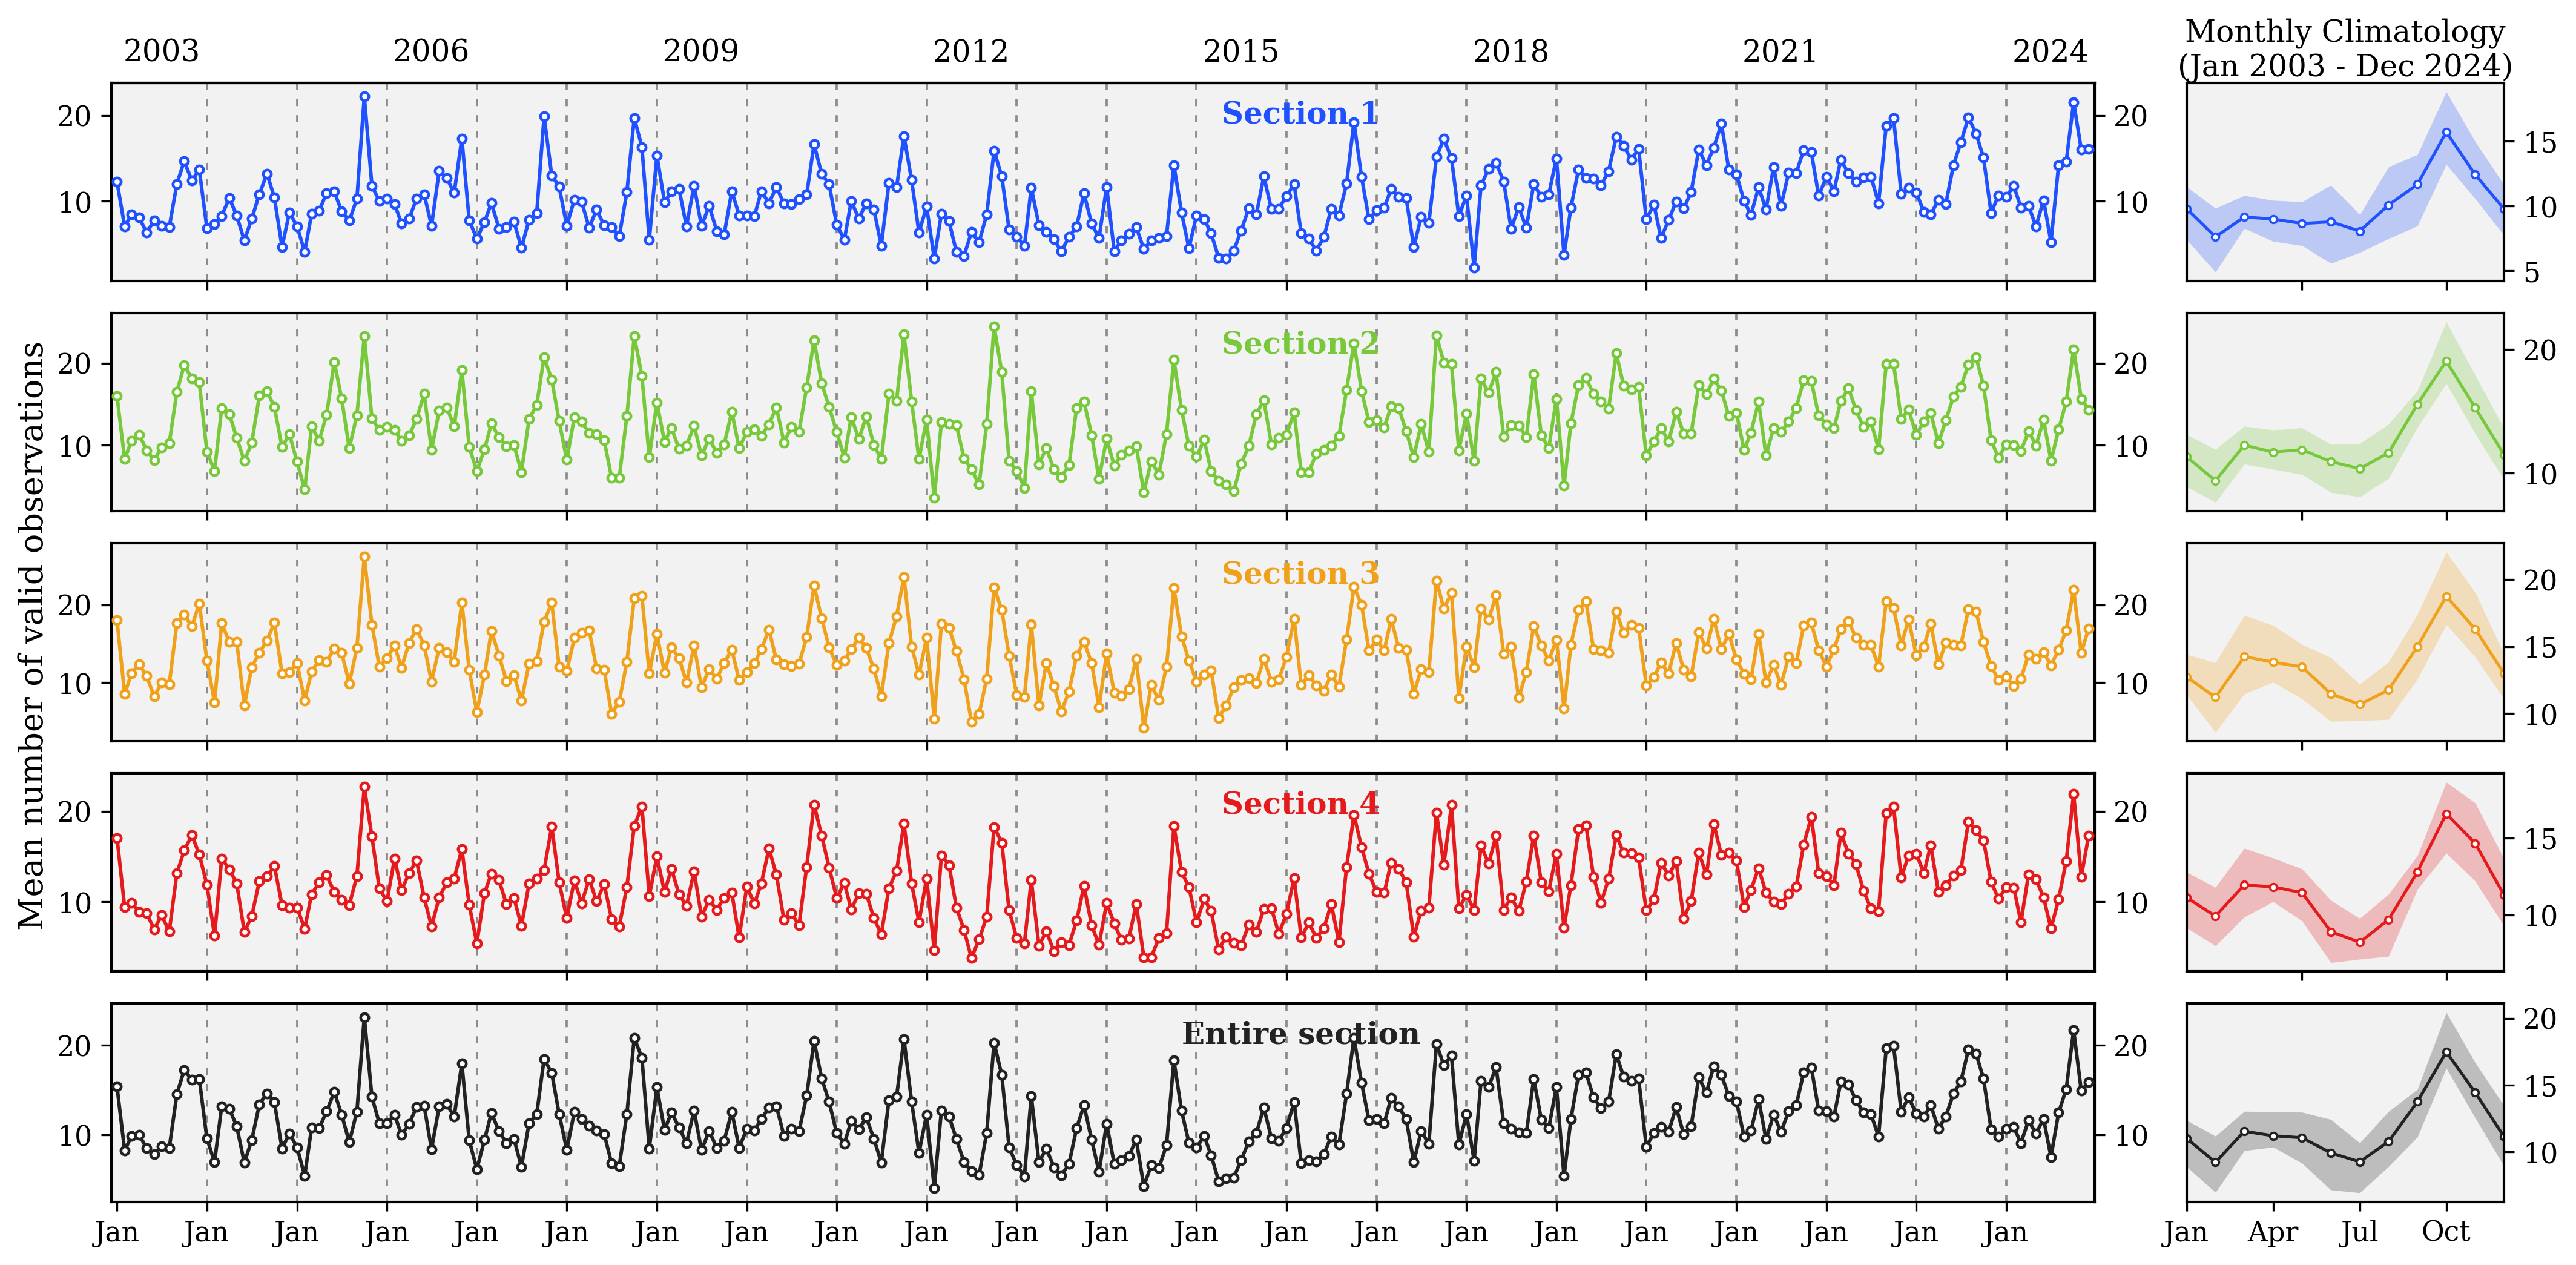

Saved: /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_mean_valid_Rrs665_days_monthly_timeseries_and_climatology.png


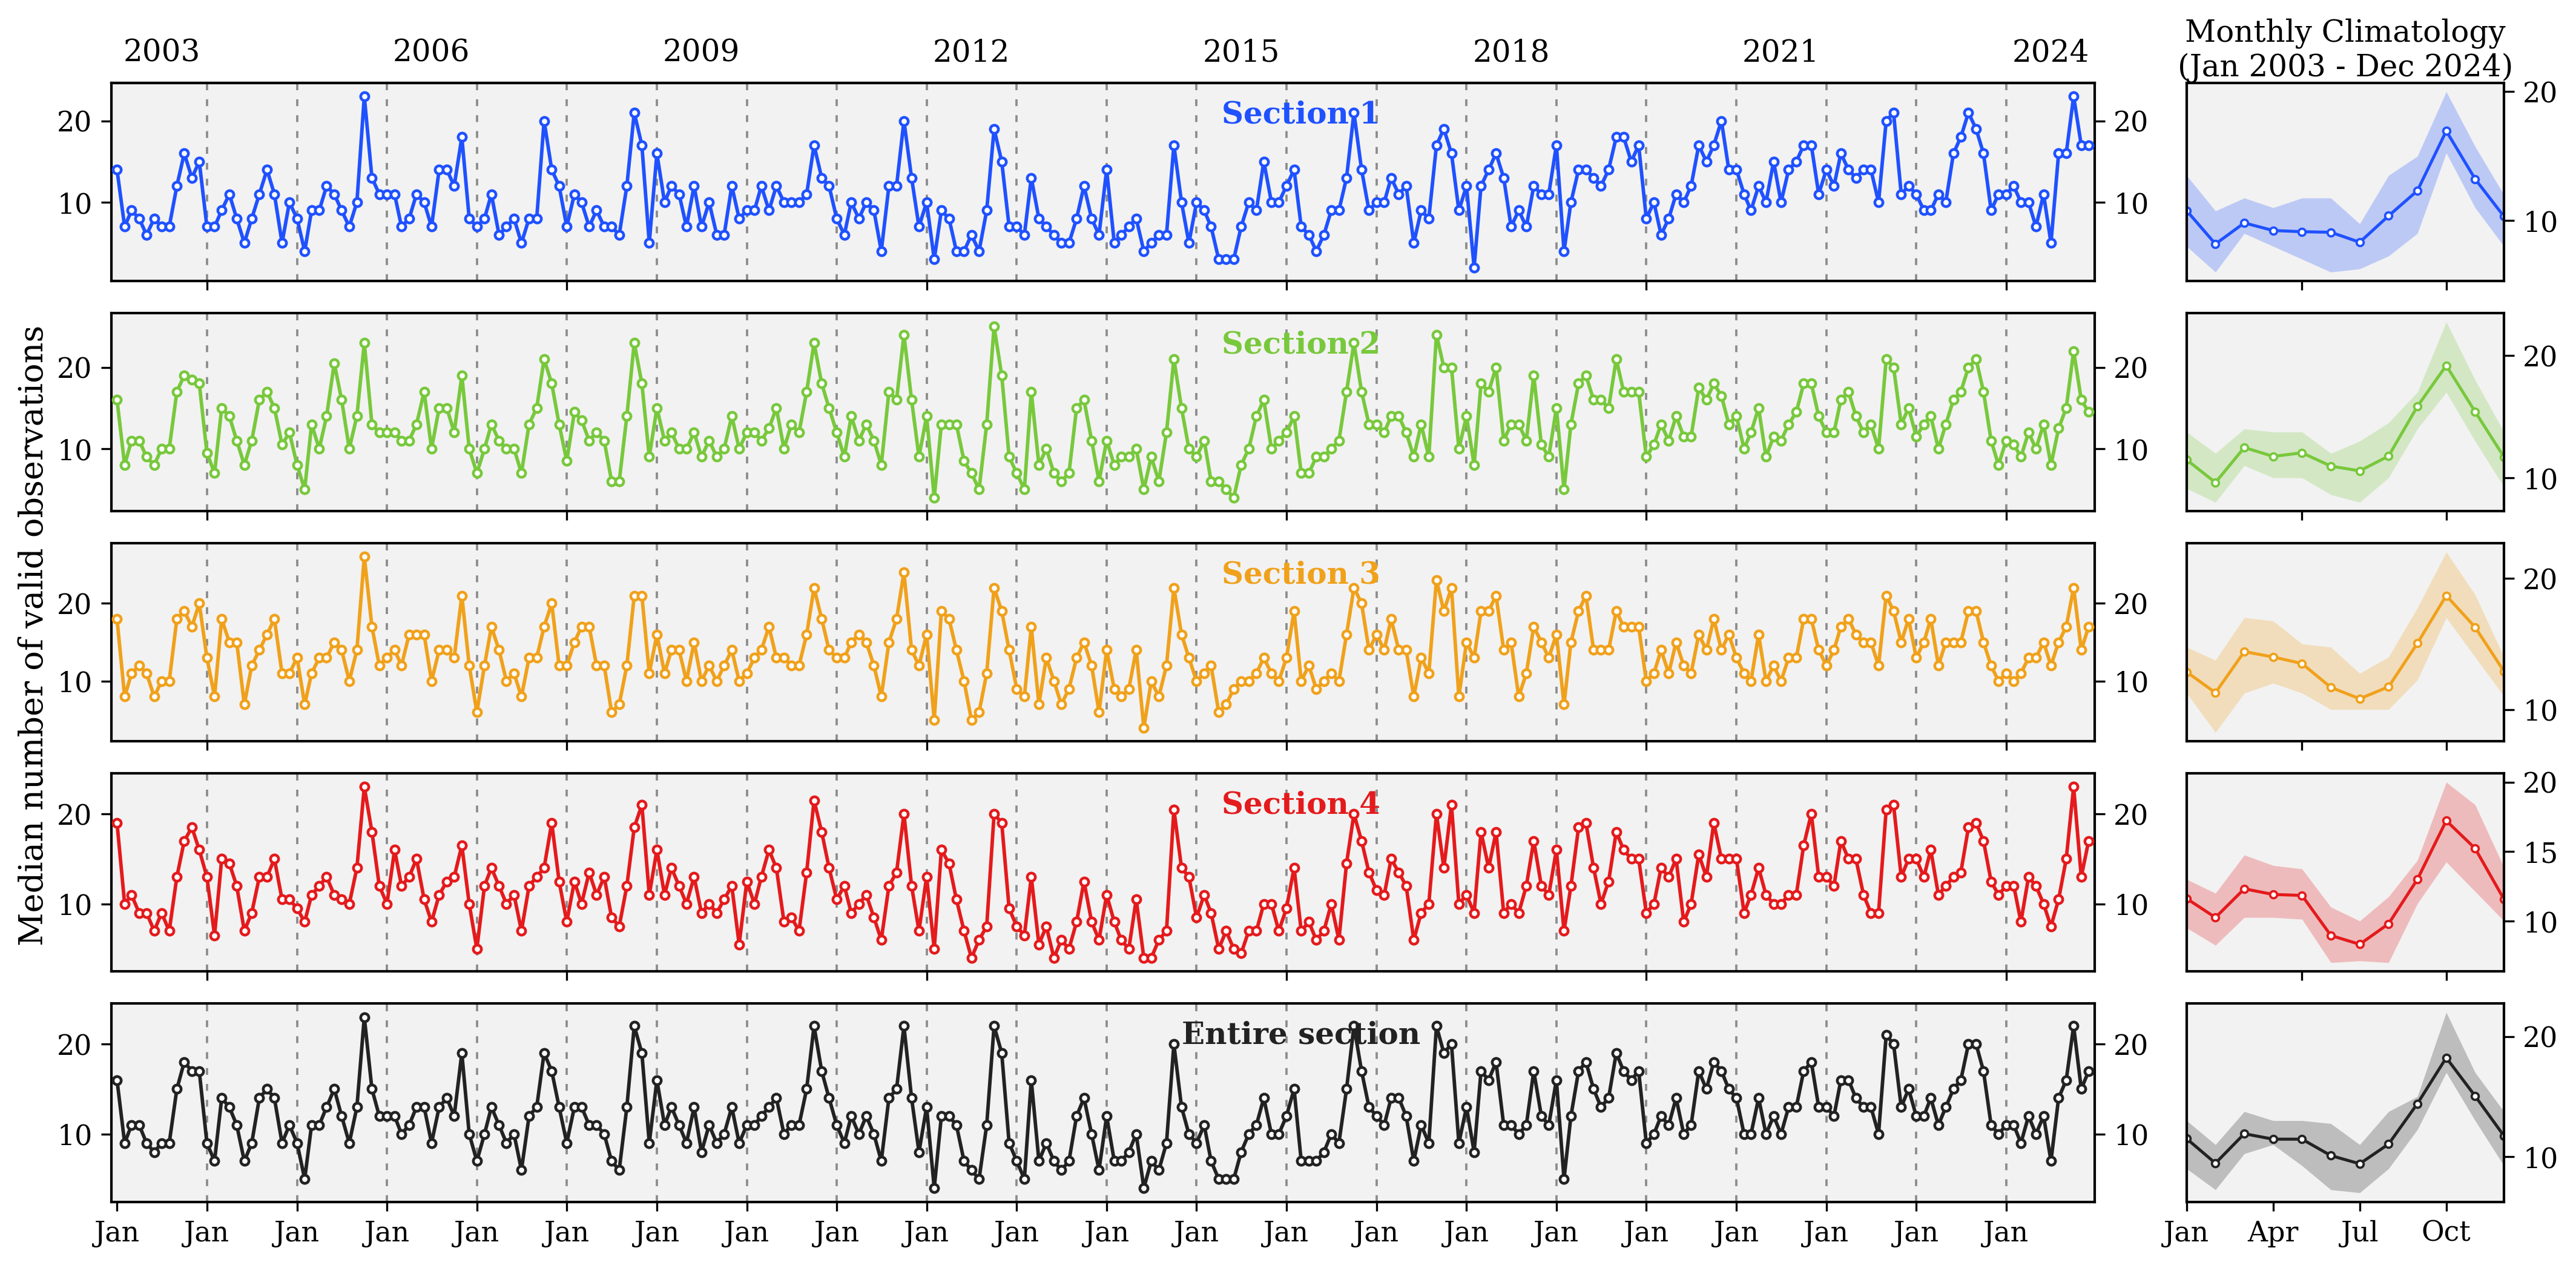

Saved: /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Louisiana_section_median_valid_Rrs665_days_monthly_timeseries_and_climatology.png


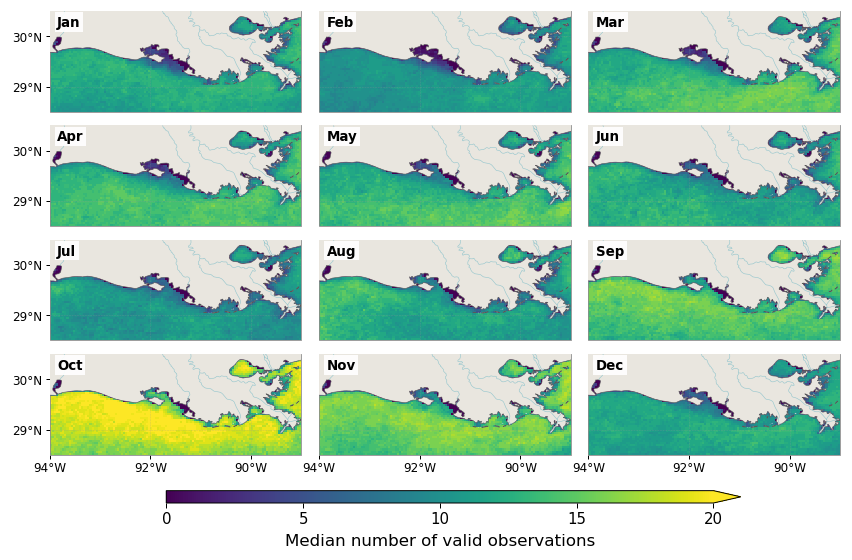

Saved: /projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts/Figure_S_OC_CCI_monthly_median_valid_observation_climatology_2003_2024.png


In [2]:
# =============================================================================
# Cell 2 — Plot section time series/climatology + 12-panel median count map
# =============================================================================
# This cell reads ONLY the processed outputs from Cell 1.
#
# Outputs
# -------
# 1) Section MEAN valid-observation monthly time series + climatology
# 2) Section MEDIAN valid-observation monthly time series + climatology
# 3) A 4 x 3 Louisiana map climatology showing, for each calendar month,
#    the pixel-wise MEDIAN monthly valid-observation count across 2003-2024.
#
# The 12-panel map follows the visual structure of:
#   Figure_S_OC_CCI_monthly_count_climatology_2003_2024.png
# but uses the daily-Rrs-based valid-observation metric instead of
# `total_nobs_sum`.
# =============================================================================

from pathlib import Path
import os
import sys
import calendar
import warnings

import numpy as np
import pandas as pd

# Keep Cartopy/PROJ on the active conda environment's database when available.
_conda_proj = Path(sys.prefix) / "share" / "proj"
if (_conda_proj / "proj.db").exists():
    os.environ["PROJ_DATA"] = str(_conda_proj)
    os.environ["PROJ_LIB"] = str(_conda_proj)

import pyproj
pyproj.datadir.set_data_dir(pyproj.datadir.get_data_dir())

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

import shapefile
from shapely.geometry import shape, box
from shapely.ops import transform as transform_geometry


# =============================================================================
# User settings
# =============================================================================
OUT_DIR = Path("/projectnb/nasa-marsh/Hangjie/Louisiana/cedric/SSC/counts")
YEAR_START = 2003
YEAR_END = 2024
PERIOD = f"{YEAR_START}_{YEAR_END}"

NPZ_IN = OUT_DIR / (
    f"Louisiana_daily_Rrs665_valid_days_by_month_{PERIOD}.npz"
)
MONTHLY_CSV = OUT_DIR / (
    f"Louisiana_section_valid_Rrs665_days_monthly_timeseries_{PERIOD}.csv"
)
CLIM_CSV = OUT_DIR / (
    f"Louisiana_section_valid_Rrs665_days_monthly_climatology_{PERIOD}.csv"
)

MEAN_FIG_OUT = OUT_DIR / (
    "Louisiana_section_mean_valid_Rrs665_days_"
    "monthly_timeseries_and_climatology.png"
)
MEDIAN_FIG_OUT = OUT_DIR / (
    "Louisiana_section_median_valid_Rrs665_days_"
    "monthly_timeseries_and_climatology.png"
)
MAP_FIG_OUT = OUT_DIR / (
    f"Figure_S_OC_CCI_monthly_median_valid_observation_"
    f"climatology_{PERIOD}.png"
)

# Optional rivers layer used in the previous OC-CCI count climatology figure.
RIVER_SHP_PATH = Path(
    "/projectnb/nasa-marsh/Hangjie/SWOT/shp/NGM_Rivers/America_River.shp"
)

# Figure settings for the section time-series figures.
YLABEL_X = 0.10
YLABEL_FONTSIZE = 13
TS_Y_PAD_FRAC = 0.08
CLIM_Y_PAD_FRAC = 0.05
YEAR_LABEL_INTERVAL = 3

# Shared output controls.
OUT_DPI = 600
SHOW_FIGURES = True

# 12-panel map settings, matching the previous count-climatology figure.
EXTENT = (-94.0, -89.0, 28.5, 30.5)
NATURAL_EARTH_SCALE = "10m"
LAND_FACE = "#e9e6df"
OCEAN_FACE = "#eef6f7"

# Use one common map scale across all 12 months.
# The upper scale is chosen from this percentile of all finite climatology
# pixels. Values above it are indicated by the colorbar's upper extension.
COLOR_PERCENTILE = 99.0
FORCE_VMAX = None


# =============================================================================
# Load processed data
# =============================================================================
monthly_df = pd.read_csv(MONTHLY_CSV, parse_dates=["date"])
clim_df = pd.read_csv(CLIM_CSV)

with np.load(NPZ_IN, allow_pickle=False) as d:
    lon = d["lon"].astype(float)
    lat = d["lat"].astype(float)

    if "pixel_median_valid_observation_climatology" not in d.files:
        raise KeyError(
            "The processed NPZ does not contain "
            "`pixel_median_valid_observation_climatology`. "
            "Run Cell 1 from this notebook first."
        )

    pixel_median_clim = (
        d["pixel_median_valid_observation_climatology"]
        .astype(np.float32)
    )

if pixel_median_clim.shape != (12, len(lat), len(lon)):
    raise ValueError(
        "Unexpected pixel climatology shape: "
        f"{pixel_median_clim.shape}; expected "
        f"(12, {len(lat)}, {len(lon)})."
    )

required_monthly = {
    "date",
    "year",
    "month",
    "section",
    "mean_valid_days_per_eligible_pixel",
    "median_valid_days_per_eligible_pixel",
}
missing_monthly = required_monthly.difference(monthly_df.columns)
if missing_monthly:
    raise ValueError(
        f"Monthly table is missing columns: {sorted(missing_monthly)}"
    )

required_clim = {
    "month",
    "section",
    "metric",
    "mean",
    "p25",
    "p75",
}
missing_clim = required_clim.difference(clim_df.columns)
if missing_clim:
    raise ValueError(
        f"Climatology table is missing columns: {sorted(missing_clim)}"
    )


# =============================================================================
# Shared section definitions
# =============================================================================
section_order = [
    "Section-1",
    "Section-2",
    "Section-3",
    "Section-4",
    "Entire Section",
]

section_order = [
    section for section in section_order
    if section in set(monthly_df["section"])
]

section_display = {
    "Section-1": "Section 1",
    "Section-2": "Section 2",
    "Section-3": "Section 3",
    "Section-4": "Section 4",
    "Entire Section": "Entire section",
}

color_map = {
    "Section-1": "#1f51ff",
    "Section-2": "#78c83c",
    "Section-3": "#f0a11b",
    "Section-4": "#e41a1c",
    "Entire Section": "#222222",
}


# =============================================================================
# Helpers for the section time-series figures
# =============================================================================
def compute_axis_limits(values, pad_frac=0.08, default=(0.0, 31.5)):
    """Return dynamic y-limits within the physical 0-31 day range."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return default

    ymin = float(np.nanmin(values))
    ymax = float(np.nanmax(values))
    value_range = ymax - ymin

    if value_range > 0:
        pad = pad_frac * value_range
    else:
        pad = max(0.5, 0.08 * abs(ymax) if ymax != 0 else 1.0)

    lower = max(0.0, ymin - pad)
    upper = min(31.5, ymax + pad)

    if upper <= lower:
        upper = min(31.5, lower + 1.0)

    return lower, upper


def make_count_figure(value_col, output_png, statistic_label):
    """
    Plot one five-row section figure for a selected spatial statistic.

    `statistic_label` is intentionally short because the metric definition is
    already established in Cell 1 and in the figure caption.
    """
    metric_clim = clim_df[clim_df["metric"] == value_col].copy()

    if metric_clim.empty:
        raise ValueError(
            f"No climatology rows were found for metric {value_col!r}. "
            "Run Cell 1 from this notebook first."
        )

    plt.rcParams.update(
        {
            "font.family": "serif",
            "font.size": 11,
            "axes.linewidth": 1.0,
            "xtick.direction": "out",
            "ytick.direction": "out",
        }
    )

    fig = plt.figure(figsize=(17, 8), dpi=300)
    gs = GridSpec(
        nrows=len(section_order),
        ncols=2,
        width_ratios=[12.5, 2.0],
        hspace=0.16,
        wspace=0.08,
        figure=fig,
    )

    all_dates = pd.to_datetime(monthly_df["date"])
    first_year = int(all_dates.dt.year.min())
    last_year = int(all_dates.dt.year.max())

    # Keep annual dashed separators, as in the SSC reference figure.
    all_years = np.arange(first_year, last_year + 1)

    # Show top-axis year labels every three years.
    labeled_years = np.arange(
        first_year,
        last_year + 1,
        YEAR_LABEL_INTERVAL,
    )

    left_axes = []

    for i, label in enumerate(section_order):
        ax_ts = fig.add_subplot(gs[i, 0])
        ax_clim = fig.add_subplot(gs[i, 1])
        left_axes.append(ax_ts)

        color = color_map[label]

        sub = (
            monthly_df[monthly_df["section"] == label]
            .sort_values("date")
            .reset_index(drop=True)
        )
        dates = pd.to_datetime(sub["date"])
        y = sub[value_col].to_numpy(dtype=float)

        clim_sub = (
            metric_clim[metric_clim["section"] == label]
            .sort_values("month")
            .reset_index(drop=True)
        )

        ts_ymin, ts_ymax = compute_axis_limits(
            y,
            pad_frac=TS_Y_PAD_FRAC,
            default=(0.0, 31.5),
        )

        clim_candidates = np.concatenate(
            [
                clim_sub["mean"].to_numpy(dtype=float),
                clim_sub["p25"].to_numpy(dtype=float),
                clim_sub["p75"].to_numpy(dtype=float),
            ]
        )
        clim_ymin, clim_ymax = compute_axis_limits(
            clim_candidates,
            pad_frac=CLIM_Y_PAD_FRAC,
            default=(0.0, 31.5),
        )

        # ---------------------------------------------------------------------
        # Left panel: monthly time series
        # ---------------------------------------------------------------------
        ax_ts.set_facecolor("#f2f2f2")

        for year in all_years[1:]:
            ax_ts.axvline(
                pd.Timestamp(f"{year}-01-01"),
                color="0.55",
                lw=0.9,
                ls=(0, (3, 4)),
                zorder=0,
            )

        ax_ts.plot(
            dates,
            y,
            color=color,
            lw=1.4,
            marker="o",
            ms=3.2,
            mfc="white",
            mec=color,
            mew=1.1,
            zorder=3,
        )

        ax_ts.set_ylim(ts_ymin, ts_ymax)
        ax_ts.tick_params(
            axis="y",
            right=True,
            labelright=True,
            length=4,
        )

        # Keep the panel annotation intentionally concise.
        ax_ts.text(
            0.60,
            0.84,
            section_display[label],
            color=color,
            transform=ax_ts.transAxes,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
        )

        if i < len(section_order) - 1:
            ax_ts.tick_params(axis="x", labelbottom=False)
        else:
            # Label January only; July labels are intentionally omitted.
            ax_ts.xaxis.set_major_locator(
                mdates.MonthLocator(bymonth=[1])
            )
            ax_ts.xaxis.set_major_formatter(
                mdates.DateFormatter("%b")
            )

        if i == 0:
            secax = ax_ts.secondary_xaxis("top")
            top_ticks = [
                pd.Timestamp(f"{year}-07-01")
                for year in labeled_years
            ]
            secax.set_xticks(top_ticks)
            secax.set_xticklabels(
                [str(year) for year in labeled_years]
            )
            secax.tick_params(
                length=0,
                pad=6,
                labelsize=12,
            )

        # ---------------------------------------------------------------------
        # Right panel: monthly climatology
        # ---------------------------------------------------------------------
        ax_clim.set_facecolor("#f2f2f2")

        months = clim_sub["month"].to_numpy(dtype=int)
        clim_mean = clim_sub["mean"].to_numpy(dtype=float)
        p25 = clim_sub["p25"].to_numpy(dtype=float)
        p75 = clim_sub["p75"].to_numpy(dtype=float)

        ax_clim.fill_between(
            months,
            p25,
            p75,
            color=color,
            alpha=0.25,
            lw=0,
        )
        ax_clim.plot(
            months,
            clim_mean,
            color=color,
            lw=1.2,
            marker="o",
            ms=2.8,
            mfc="white",
            mec=color,
            mew=0.9,
        )

        ax_clim.set_xlim(1, 12)
        ax_clim.set_ylim(clim_ymin, clim_ymax)
        ax_clim.tick_params(
            axis="y",
            left=False,
            labelleft=False,
            right=True,
            labelright=True,
            length=4,
        )

        if i < len(section_order) - 1:
            ax_clim.tick_params(
                axis="x",
                labelbottom=False,
            )
        else:
            ax_clim.set_xticks([1, 4, 7, 10])
            ax_clim.set_xticklabels(
                ["Jan", "Apr", "Jul", "Oct"]
            )

        if i == 0:
            start_date = all_dates.min().strftime("%b %Y")
            end_date = all_dates.max().strftime("%b %Y")
            ax_clim.set_title(
                f"Monthly Climatology\n({start_date} - {end_date})",
                fontsize=12,
                pad=2,
            )

    # Requested short y-axis labels.
    fig.text(
        YLABEL_X,
        0.5,
        statistic_label,
        rotation=90,
        va="center",
        ha="center",
        fontsize=YLABEL_FONTSIZE,
    )

    for ax in left_axes:
        ax.margins(x=0.003)

    fig.savefig(
        output_png,
        dpi=OUT_DPI,
        bbox_inches="tight",
    )

    if SHOW_FIGURES:
        plt.show()

    plt.close(fig)
    print(f"Saved: {output_png}")


# =============================================================================
# Helpers for the 12-panel Louisiana map
# =============================================================================
def _edges(centers):
    """Convert monotonically ordered grid-cell centers to cell edges."""
    centers = np.asarray(centers, dtype=float)
    delta = np.diff(centers)

    if not (np.all(delta > 0) or np.all(delta < 0)):
        raise ValueError("Grid coordinates must be strictly monotonic.")

    return np.r_[
        centers[0] - delta[0] / 2,
        (centers[:-1] + centers[1:]) / 2,
        centers[-1] + delta[-1] / 2,
    ]


def _read_vectors(path):
    """Read and transform a shapefile to geographic WGS84 coordinates."""
    if not path.is_file():
        raise FileNotFoundError(path)

    prj = path.with_suffix(".prj")
    if not prj.is_file():
        raise ValueError(f"Missing CRS file: {prj}")

    source_crs = pyproj.CRS.from_wkt(prj.read_text())
    target_crs = pyproj.CRS.from_epsg(4326)
    transformer = pyproj.Transformer.from_crs(
        source_crs,
        target_crs,
        always_xy=True,
    )

    geometries = []

    with shapefile.Reader(str(path)) as reader:
        for shp in reader.iterShapes():
            if shp.shapeType == 0:
                continue

            geom = shape(shp.__geo_interface__)
            geom = transform_geometry(
                transformer.transform,
                geom,
            )

            if geom.is_empty:
                continue

            if not geom.is_valid:
                geom = geom.buffer(0)

            if not geom.is_empty:
                geometries.append(geom)

    return geometries


def _load_rivers():
    """Load the optional river layer and clip it to the displayed domain."""
    if not RIVER_SHP_PATH.exists():
        warnings.warn(
            f"Optional river layer not found: {RIVER_SHP_PATH}. "
            "The map will be drawn without rivers."
        )
        return []

    try:
        domain = box(
            EXTENT[0],
            EXTENT[2],
            EXTENT[1],
            EXTENT[3],
        )

        rivers = []
        for geom in _read_vectors(RIVER_SHP_PATH):
            if geom.intersects(domain):
                clipped = geom.intersection(domain)
                if not clipped.is_empty:
                    rivers.append(clipped)

        return rivers

    except Exception as exc:
        warnings.warn(
            f"Optional river layer omitted because it could not be read: {exc}"
        )
        return []


def _adaptive_colorbar(fig, cb, max_labels=7):
    """Choose sparse colorbar ticks that do not overlap when rendered."""
    for budget in range(max_labels, 1, -1):
        locator = mticker.MaxNLocator(
            nbins=budget - 1,
            steps=[1, 2, 2.5, 5, 10],
            min_n_ticks=2,
        )

        ticks = locator.tick_values(
            cb.norm.vmin,
            cb.norm.vmax,
        )
        ticks = ticks[
            (ticks >= cb.norm.vmin)
            & (ticks <= cb.norm.vmax)
        ]

        if ticks.size < 2:
            ticks = np.array(
                [cb.norm.vmin, cb.norm.vmax]
            )

        cb.set_ticks(ticks)
        cb.ax.xaxis.set_major_formatter(
            mticker.FuncFormatter(
                lambda x, pos: f"{x:,.4g}"
            )
        )
        cb.ax.minorticks_off()

        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

        boxes = [
            tick.get_window_extent(renderer)
            for tick in cb.ax.get_xticklabels()
            if tick.get_visible()
        ]

        gap = 9 * fig.dpi / 72.0

        if all(
            a.x1 + gap < b.x0
            for a, b in zip(boxes[:-1], boxes[1:])
        ):
            break


def _map_panel(
    ax,
    z,
    lon,
    lat,
    rivers,
    norm,
    cmap,
    bottom=True,
    left=True,
):
    """Draw one compact monthly Louisiana climatology panel."""
    crs = ccrs.PlateCarree()

    ax.set_extent(EXTENT, crs=crs)
    ax.set_facecolor(OCEAN_FACE)

    image = ax.pcolormesh(
        _edges(lon),
        _edges(lat),
        np.ma.masked_invalid(z),
        transform=crs,
        shading="flat",
        cmap=cmap,
        norm=norm,
        zorder=1,
    )

    ax.add_feature(
        cfeature.LAND.with_scale(NATURAL_EARTH_SCALE),
        facecolor=LAND_FACE,
        edgecolor="none",
        zorder=3,
    )

    ax.coastlines(
        resolution=NATURAL_EARTH_SCALE,
        color="0.35",
        linewidth=0.35,
        zorder=4,
    )

    if rivers:
        ax.add_geometries(
            rivers,
            crs,
            facecolor="none",
            edgecolor="#94c6cd",
            linewidth=0.35,
            zorder=5,
        )

    xticks = [-94, -92, -90]
    yticks = [29, 30]

    ax.set_xticks(xticks, crs=crs)
    ax.set_yticks(yticks, crs=crs)

    ax.xaxis.set_major_formatter(
        LongitudeFormatter(number_format=".0f")
    )
    ax.yaxis.set_major_formatter(
        LatitudeFormatter(number_format="g")
    )

    ax.tick_params(
        labelbottom=bottom,
        labelleft=left,
        bottom=bottom,
        left=left,
        top=False,
        right=False,
        labelsize=7.2,
        pad=2,
        length=2.5,
        width=0.6,
    )

    gridlines = ax.gridlines(
        draw_labels=False,
        linewidth=0.3,
        color="0.6",
        alpha=0.4,
        linestyle="--",
        zorder=6,
    )
    gridlines.xlocator = mticker.FixedLocator(xticks)
    gridlines.ylocator = mticker.FixedLocator(yticks)

    ax.spines["geo"].set_linewidth(0.5)
    ax.spines["geo"].set_edgecolor("0.55")

    return image


def _choose_map_scale(climatology):
    """Create one shared color scale for all twelve monthly panels."""
    finite = climatology[np.isfinite(climatology)]

    if finite.size == 0:
        raise ValueError(
            "No finite pixel-wise median climatology values were found."
        )

    if not (0 < COLOR_PERCENTILE <= 100):
        raise ValueError(
            "COLOR_PERCENTILE must be in (0, 100]."
        )

    reference = float(
        np.nanpercentile(
            finite,
            COLOR_PERCENTILE,
        )
    )

    if reference <= 0:
        reference = max(
            1.0,
            float(np.nanmax(finite)),
        )

    suggested = mticker.MaxNLocator(
        nbins=6,
        steps=[1, 2, 2.5, 5, 10],
    ).tick_values(0, reference)[-1]

    vmax = (
        float(FORCE_VMAX)
        if FORCE_VMAX is not None
        else float(suggested)
    )

    # The daily valid-observation metric cannot exceed 31.
    vmax = min(vmax, 31.0)

    if not np.isfinite(vmax) or vmax <= 0:
        raise ValueError(
            "The selected map vmax must be positive and finite."
        )

    extend = (
        "max"
        if float(np.nanmax(finite)) > vmax
        else "neither"
    )

    return Normalize(
        vmin=0,
        vmax=vmax,
        clip=False,
    ), extend


def make_monthly_median_map():
    """
    Make a 4 x 3 pixel-wise median valid-observation climatology map.

    For each pixel and calendar month, the mapped value is the median of that
    pixel's monthly valid-day count across the 2003-2024 years.
    """
    norm, extend = _choose_map_scale(
        pixel_median_clim
    )

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad(OCEAN_FACE)
    cmap.set_over(cmap(1.0))

    rivers = _load_rivers()

    with plt.rc_context(
        {
            "font.family": "sans-serif",
            "font.sans-serif": [
                "Arial",
                "DejaVu Sans",
            ],
            "font.size": 9,
            "axes.linewidth": 0.7,
            "savefig.dpi": OUT_DPI,
        }
    ):
        fig = plt.figure(
            figsize=(7.2, 5.15),
            dpi=120,
        )

        grid = fig.add_gridspec(
            4,
            3,
            left=0.07,
            right=0.985,
            bottom=0.205,
            top=0.925,
            wspace=0.07,
            hspace=0.12,
        )

        image = None

        for month_index in range(12):
            row, col = divmod(
                month_index,
                3,
            )

            ax = fig.add_subplot(
                grid[row, col],
                projection=ccrs.PlateCarree(),
            )

            image = _map_panel(
                ax=ax,
                z=pixel_median_clim[month_index],
                lon=lon,
                lat=lat,
                rivers=rivers,
                norm=norm,
                cmap=cmap,
                bottom=(row == 3),
                left=(col == 0),
            )

            ax.text(
                0.03,
                0.96,
                calendar.month_abbr[
                    month_index + 1
                ],
                transform=ax.transAxes,
                fontsize=8,
                weight="bold",
                ha="left",
                va="top",
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.92,
                    pad=1.6,
                ),
                zorder=12,
            )

        cax = fig.add_axes(
            [0.205, 0.128, 0.665, 0.020]
        )

        cb = fig.colorbar(
            image,
            cax=cax,
            orientation="horizontal",
            extend=extend,
        )

        cb.set_label(
            "Median number of valid observations",
            fontsize=10,
            labelpad=4,
        )

        cb.ax.tick_params(
            labelsize=9,
            length=3,
            width=0.6,
            pad=2,
        )
        cb.outline.set_linewidth(0.6)
        _adaptive_colorbar(fig, cb)

        fig.savefig(
            MAP_FIG_OUT,
            dpi=OUT_DPI,
            facecolor="white",
            bbox_inches="tight",
            pad_inches=0.045,
        )

        if SHOW_FIGURES:
            plt.show()

        plt.close(fig)

    print(f"Saved: {MAP_FIG_OUT}")


# =============================================================================
# Generate all requested figures
# =============================================================================
make_count_figure(
    value_col="mean_valid_days_per_eligible_pixel",
    output_png=MEAN_FIG_OUT,
    statistic_label="Mean number of valid observations",
)

make_count_figure(
    value_col="median_valid_days_per_eligible_pixel",
    output_png=MEDIAN_FIG_OUT,
    statistic_label="Median number of valid observations",
)

make_monthly_median_map()
